In [2]:
import sys

print(sys.executable)

d:\Desktop\Dl_projects1\movie-recommendation-system\.venv\Scripts\python.exe


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
movies = pd.read_csv("data/ml-latest/movies.csv")


movies.head()



,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [5]:
movies.shape

(86537, 3)

In [6]:
movies.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 86537 entries, 0 to 86536
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   movieId  86537 non-null  int64 
 1   title    86537 non-null  object
 2   genres   86537 non-null  object
dtypes: int64(1), object(2)
memory usage: 2.0+ MB


In [7]:
movies.duplicated().sum()

np.int64(0)

In [8]:
movies['movieId'].duplicated().sum()

np.int64(0)

In [9]:
genre_counts = movies['genres'].str.split('|').explode().value_counts()

genre_counts

genres
Drama                 33681
Comedy                22830
Thriller              11675
Romance               10172
Action                 9563
Documentary            9283
Horror                 8570
(no genres listed)     7060
Crime                  6917
Adventure              5349
Sci-Fi                 4850
Animation              4579
Children               4367
Mystery                3972
Fantasy                3821
War                    2301
Western                1690
Musical                1059
Film-Noir               354
IMAX                    195
Name: count, dtype: int64

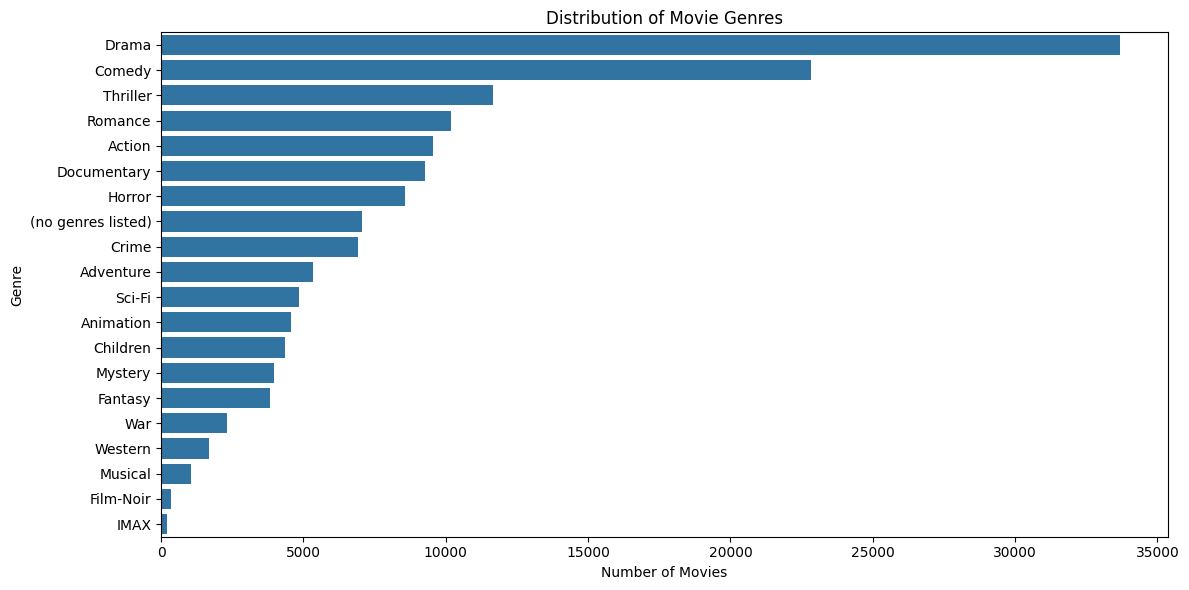

In [10]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=genre_counts.values,
    y=genre_counts.index
)

plt.title("Distribution of Movie Genres")
plt.xlabel("Number of Movies")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()

In [11]:
movies['year'] = movies['title'].str.extract(r'\((\d{4})\)')

movies[['title', 'year']].head(10)

,title,year
0,Toy Story (1995),1995
1,Jumanji (1995),1995
2,Grumpier Old Men (1995),1995
3,Waiting to Exhale (1995),1995
4,Father of the Bride Part II (1995),1995
5,Heat (1995),1995
6,Sabrina (1995),1995
7,Tom and Huck (1995),1995
8,Sudden Death (1995),1995
9,GoldenEye (1995),1995


In [12]:
# print("Missing years:", movies['year'].isnull().sum())

# print("\nData types:")
# print(movies.dtypes)

# print("\nYear range:")
# print(movies['year'].min(), "-", movies['year'].max())

cleaning year coloumn


In [13]:
movies['year'] = pd.to_numeric(movies['year'], errors='coerce')

print("Data type:", movies['year'].dtype)
print("Missing years:", movies['year'].isnull().sum())

print("Year range:",
      movies['year'].min(),
      "-",
      movies['year'].max())

Data type: float64
Missing years: 618
Year range: 1874.0 - 2023.0


movie releases overtime

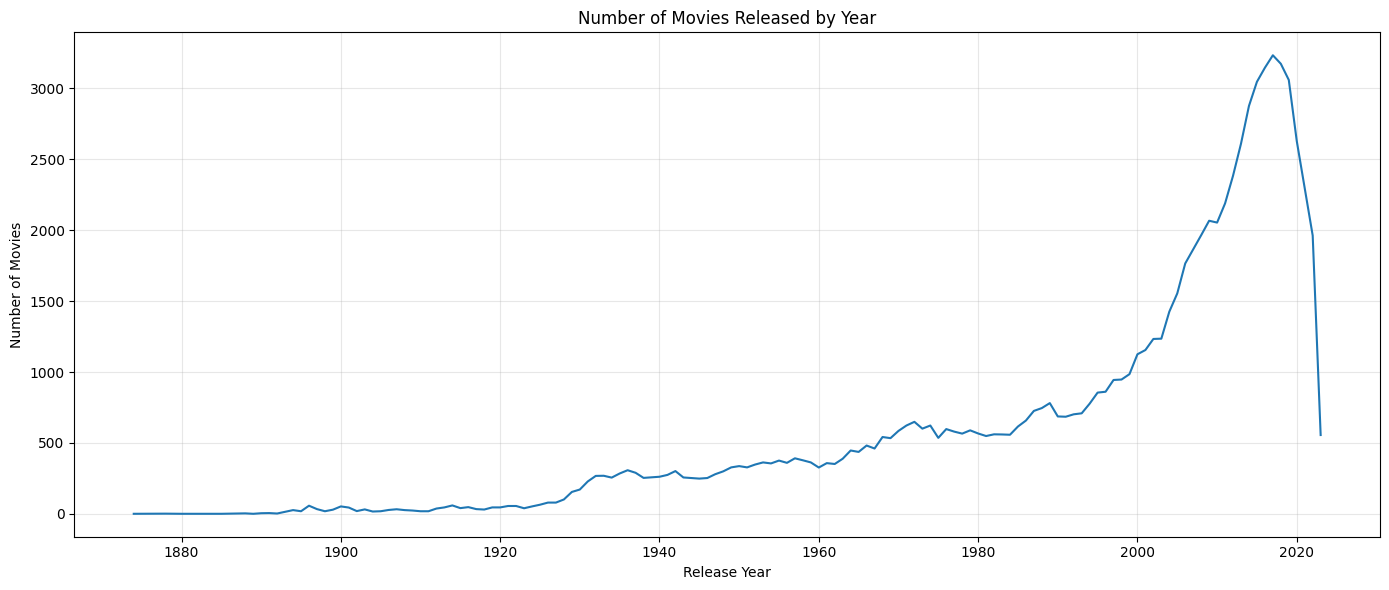

In [14]:
year_counts = movies['year'].value_counts().sort_index()

plt.figure(figsize=(14, 6))

plt.plot(year_counts.index, year_counts.values)

plt.title("Number of Movies Released by Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Movies")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [15]:
# most productive decade

movies['decade'] = (movies['year'] // 10) * 10

decade_counts = movies['decade'].value_counts().sort_index()

decade_counts

decade_counts.sort_values(ascending=False).head(5)

print("Most represented decade:", decade_counts.idxmax())
print("Number of movies:", decade_counts.max())

Most represented decade: 2010.0
Number of movies: 27759


In [16]:
ratings_preview = pd.read_csv(
    "data/ml-latest/ratings.csv",
    nrows=10
)

ratings_preview

,userId,movieId,rating,timestamp
0,1,1,4.0,1225734739
1,1,110,4.0,1225865086
2,1,158,4.0,1225733503
3,1,260,4.5,1225735204
4,1,356,5.0,1225735119
5,1,381,3.5,1225734105
6,1,596,4.0,1225733524
7,1,1036,5.0,1225735626
8,1,1049,3.0,1225734079
9,1,1066,4.0,1225736961


rating_preview distribution across the movies

In [17]:
ratings_preview['rating'].value_counts().sort_index()

rating
3.0    1
3.5    1
4.0    5
4.5    1
5.0    2
Name: count, dtype: int64

In [18]:
total_rows = 0

for chunk in pd.read_csv(
    "data/ml-latest/ratings.csv",
    chunksize=500_000
):
    total_rows += len(chunk)

print("Total ratings:", total_rows)

Total ratings: 33832162


In [19]:
rating_counts = pd.Series(dtype='int64')

for chunk in pd.read_csv(
    "data/ml-latest/ratings.csv",
    chunksize=500_000
):
    counts = chunk['rating'].value_counts()
    rating_counts = rating_counts.add(counts, fill_value=0)

rating_counts = rating_counts.sort_index().astype(int)

rating_counts

rating
0.5     566306
1.0    1013645
1.5     562409
2.0    2146492
2.5    1760733
3.0    6400664
3.5    4465001
4.0    8835955
4.5    3123055
5.0    4957902
dtype: int64

In [20]:
average_rating = (
    (rating_counts.index.to_numpy() * rating_counts.values).sum()
    / rating_counts.sum()
)

print("Average rating:", round(average_rating, 2))

Average rating: 3.54


In [21]:
movie_rating_counts = pd.Series(dtype='int64')

for chunk in pd.read_csv(
    "data/ml-latest/ratings.csv",
    chunksize=500_000
):
    counts = chunk['movieId'].value_counts()
    movie_rating_counts = movie_rating_counts.add(
        counts, fill_value=0
    )

movie_rating_counts = movie_rating_counts.astype(int)

movie_rating_counts.sort_values(ascending=False).head(10)

movieId
318     122296
356     113581
296     108756
2571    107056
593     101802
260      97202
2959     86207
527      84232
480      83026
1196     80200
dtype: int64

In [22]:
top_10_movies = movie_rating_counts.sort_values(ascending=False).head(10)

pd.DataFrame({
    'movieId': top_10_movies.index,
    'rating_count': top_10_movies.values
}).merge(movies[['movieId', 'title']], on='movieId')

,movieId,rating_count,title
0,318,122296,"Shawshank Redemption, The (1994)"
1,356,113581,Forrest Gump (1994)
2,296,108756,Pulp Fiction (1994)
3,2571,107056,"Matrix, The (1999)"
4,593,101802,"Silence of the Lambs, The (1991)"
5,260,97202,Star Wars: Episode IV - A New Hope (1977)
6,2959,86207,Fight Club (1999)
7,527,84232,Schindler's List (1993)
8,480,83026,Jurassic Park (1993)
9,1196,80200,Star Wars: Episode V - The Empire Strikes Back...


In [23]:
movie_rating_stats = pd.DataFrame({
    'rating_count': movie_rating_counts
})

movie_rating_stats = movie_rating_stats.reset_index()
movie_rating_stats.columns = ['movieId', 'rating_count']

movie_rating_stats = movie_rating_stats.merge(
    movies[['movieId', 'title']],
    on='movieId'
)

movie_rating_stats.head()

,movieId,rating_count,title
0,1,76813,Toy Story (1995)
1,2,30209,Jumanji (1995)
2,3,15820,Grumpier Old Men (1995)
3,4,3028,Waiting to Exhale (1995)
4,5,15801,Father of the Bride Part II (1995)


In [24]:
movie_average_ratings = pd.Series(dtype='float64')

for chunk in pd.read_csv(
    "data/ml-latest/ratings.csv",
    chunksize=500_000
):
    averages = chunk.groupby('movieId')['rating'].agg(
        ['sum', 'count']
    )

    if movie_average_ratings.empty:
        movie_average_ratings = averages
    else:
        movie_average_ratings = (
            movie_average_ratings.add(averages, fill_value=0)
        )

movie_average_ratings['average_rating'] = (
    movie_average_ratings['sum'] /
    movie_average_ratings['count']
)

In [25]:
popular_movies = movie_average_ratings[
    movie_average_ratings['count'] >= 100
].copy()

popular_movies = popular_movies.sort_values(
    'average_rating',
    ascending=False
)

popular_movies = popular_movies.merge(
    movies[['movieId', 'title']],
    on='movieId'
)

popular_movies[['title', 'count', 'average_rating']].head(10)

,title,count,average_rating
0,Planet Earth II (2016),2041.0,4.451739
1,Planet Earth (2006),3015.0,4.448093
2,Band of Brothers (2001),2835.0,4.423986
3,"Shawshank Redemption, The (1994)",122296.0,4.416792
4,Cosmos,625.0,4.343200
5,Parasite (2019),12399.0,4.329946
6,"Godfather, The (1972)",75004.0,4.326603
7,Blue Planet II (2017),1267.0,4.312944
8,Twelve Angry Men (1954),332.0,4.305723
9,Twin Peaks (1989),1132.0,4.302562


Visualize the top 10 movies

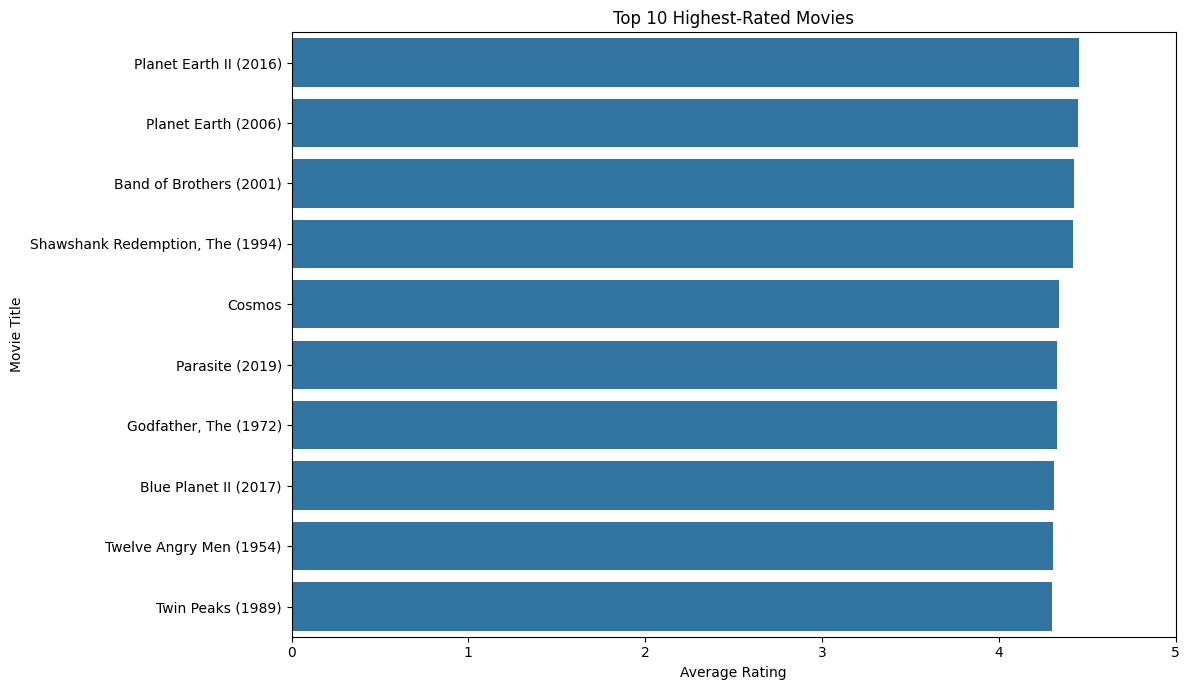

In [26]:
top_10 = popular_movies.head(10)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_10,
    x='average_rating',
    y='title'
)

plt.title('Top 10 Highest-Rated Movies')
plt.xlabel('Average Rating')
plt.ylabel('Movie Title')
plt.xlim(0, 5)

plt.tight_layout()
plt.show()

In [27]:
movie_average_ratings.head()

,sum,count,average_rating
movieId,,,
1,299072.0,76813.0,3.893508
2,99030.5,30209.0,3.278179
3,50169.5,15820.0,3.171271
4,8685.5,3028.0,2.868395
5,48619.0,15801.0,3.076957


In [28]:
movie_ratings = movie_average_ratings.merge(
    movies[['movieId', 'title', 'genres']],
    on='movieId'
)

movie_ratings.head()


,movieId,sum,count,average_rating,title,genres
0,1,299072.0,76813.0,3.893508,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,99030.5,30209.0,3.278179,Jumanji (1995),Adventure|Children|Fantasy
2,3,50169.5,15820.0,3.171271,Grumpier Old Men (1995),Comedy|Romance
3,4,8685.5,3028.0,2.868395,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,48619.0,15801.0,3.076957,Father of the Bride Part II (1995),Comedy


In [29]:
# Split multiple genres into separate lists
genre_lists = movie_ratings['genres'].str.split('|')

# Convert each genre list into individual rows
genre_data = movie_ratings.assign(
    genres=genre_lists
).explode('genres')

# Display the first 10 rows
genre_data[['title', 'genres', 'average_rating']].head(10)

,title,genres,average_rating
0,Toy Story (1995),Adventure,3.893508
0,Toy Story (1995),Animation,3.893508
0,Toy Story (1995),Children,3.893508
0,Toy Story (1995),Comedy,3.893508
0,Toy Story (1995),Fantasy,3.893508
1,Jumanji (1995),Adventure,3.278179
1,Jumanji (1995),Children,3.278179
1,Jumanji (1995),Fantasy,3.278179
2,Grumpier Old Men (1995),Comedy,3.171271
2,Grumpier Old Men (1995),Romance,3.171271


In [30]:
genre_rating_stats = genre_data.groupby('genres').agg(
    average_rating=('average_rating', 'mean'),
    total_movies=('movieId', 'nunique'),
    total_ratings=('count', 'sum')
).reset_index()

genre_rating_stats = genre_rating_stats.sort_values(
    by='average_rating',
    ascending=False
)

genre_rating_stats

,genres,average_rating,total_movies,total_ratings
7,Documentary,3.342492,8961,441100.0
10,Film-Noir,3.328275,350,318917.0
12,IMAX,3.246116,195,1560106.0
13,Musical,3.194918,1031,1239223.0
18,War,3.187157,2199,1697649.0
8,Drama,3.124365,32611,14787040.0
15,Romance,3.107959,9838,5874531.0
3,Animation,3.067294,4544,2329566.0
6,Crime,3.031253,6652,5688582.0
5,Comedy,2.992835,22132,11860141.0


Visualize average ratings by genre

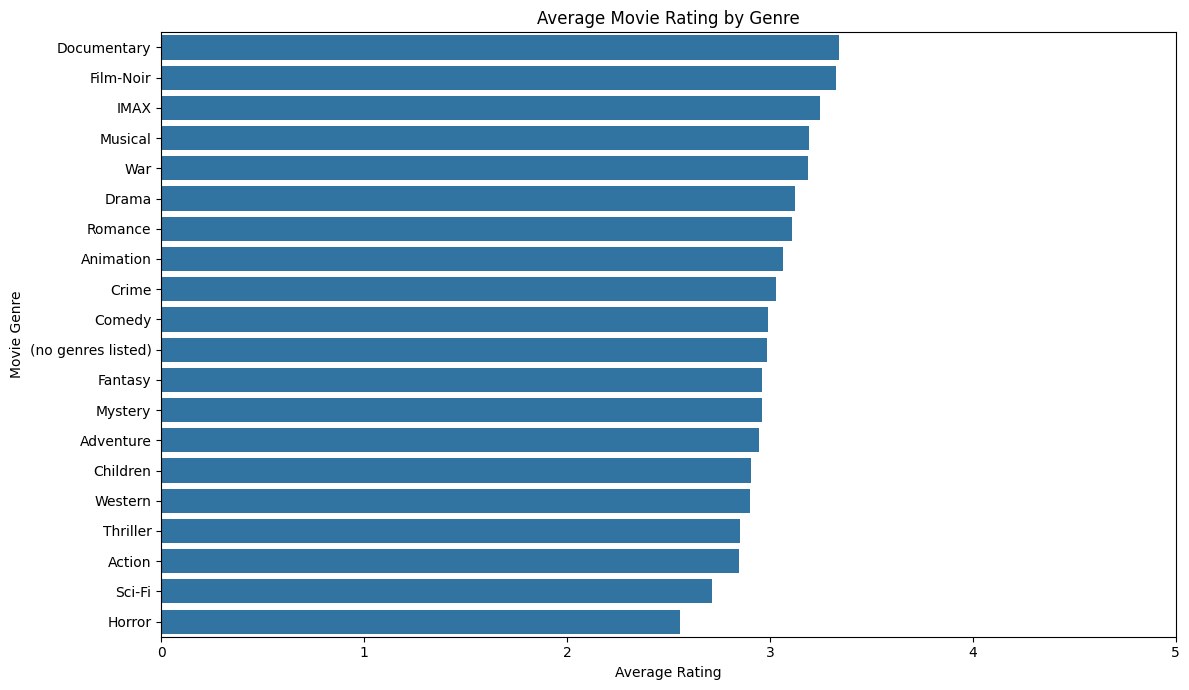

In [31]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=genre_rating_stats,
    x='average_rating',
    y='genres'
)

plt.title('Average Movie Rating by Genre')
plt.xlabel('Average Rating')
plt.ylabel('Movie Genre')
plt.xlim(0, 5)

plt.tight_layout()
plt.show()

Compare genre popularity

In [32]:
genre_popularity = genre_data.groupby('genres').agg(
    total_movies=('movieId', 'nunique'),
    total_ratings=('count', 'sum')
).reset_index()

genre_popularity = genre_popularity.sort_values(
    by='total_ratings',
    ascending=False
)

genre_popularity

,genres,total_movies,total_ratings
8,Drama,32611,14787040.0
5,Comedy,22132,11860141.0
1,Action,9195,10222144.0
17,Thriller,11413,9168628.0
2,Adventure,5100,8048929.0
16,Sci-Fi,4737,6032230.0
15,Romance,9838,5874531.0
6,Crime,6652,5688582.0
9,Fantasy,3750,3899930.0
4,Children,4292,2897960.0


Visualize genre popularity

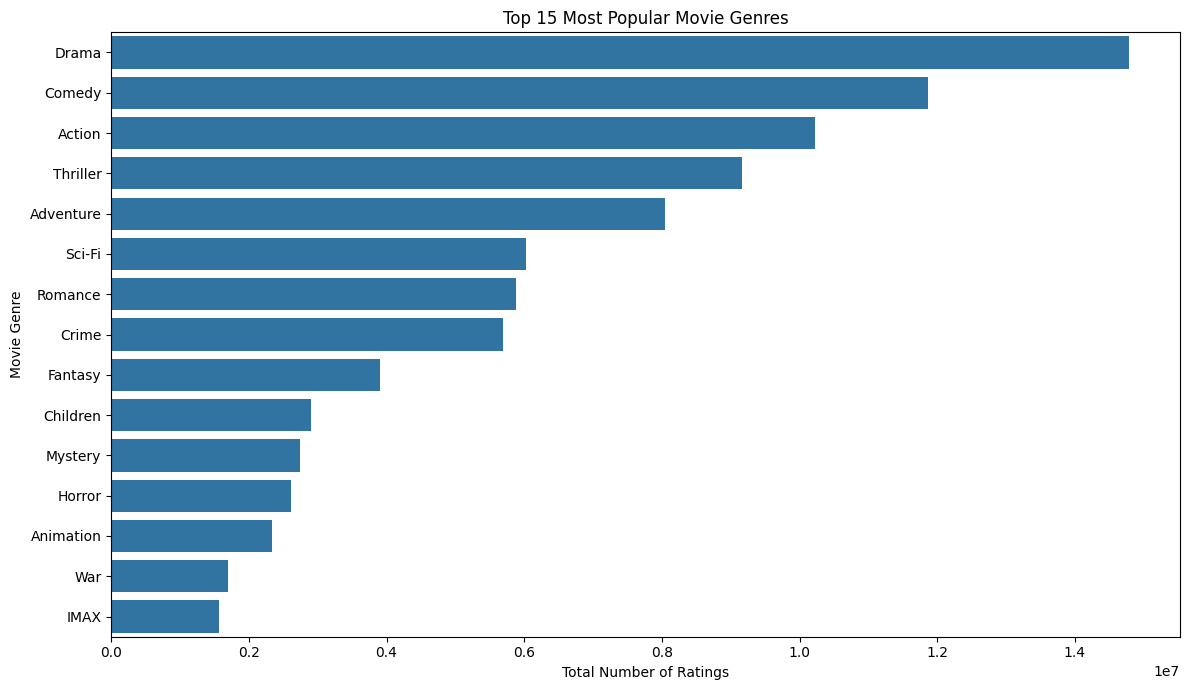

In [33]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=genre_popularity.head(15),
    x='total_ratings',
    y='genres'
)

plt.title('Top 15 Most Popular Movie Genres')
plt.xlabel('Total Number of Ratings')
plt.ylabel('Movie Genre')

plt.tight_layout()
plt.show()

Calculate weighted average ratings by genre

In [34]:
genre_weighted_ratings = genre_data.groupby('genres').agg(
    total_rating_points=('sum', 'sum'),
    total_ratings=('count', 'sum')
).reset_index()

genre_weighted_ratings['weighted_average_rating'] = (
    genre_weighted_ratings['total_rating_points'] /
    genre_weighted_ratings['total_ratings']
)

genre_weighted_ratings = genre_weighted_ratings.sort_values(
    by='weighted_average_rating',
    ascending=False
)

genre_weighted_ratings

,genres,total_rating_points,total_ratings,weighted_average_rating
10,Film-Noir,1248867.0,318917.0,3.915962
18,War,6446958.5,1697649.0,3.797580
6,Crime,21031827.5,5688582.0,3.697200
7,Documentary,1628806.0,441100.0,3.692600
8,Drama,54502646.0,14787040.0,3.685839
14,Mystery,10097611.5,2748373.0,3.674032
3,Animation,8422687.5,2329566.0,3.615561
12,IMAX,5627094.0,1560106.0,3.606866
19,Western,2272639.5,632052.0,3.595653
13,Musical,4396877.0,1239223.0,3.548092


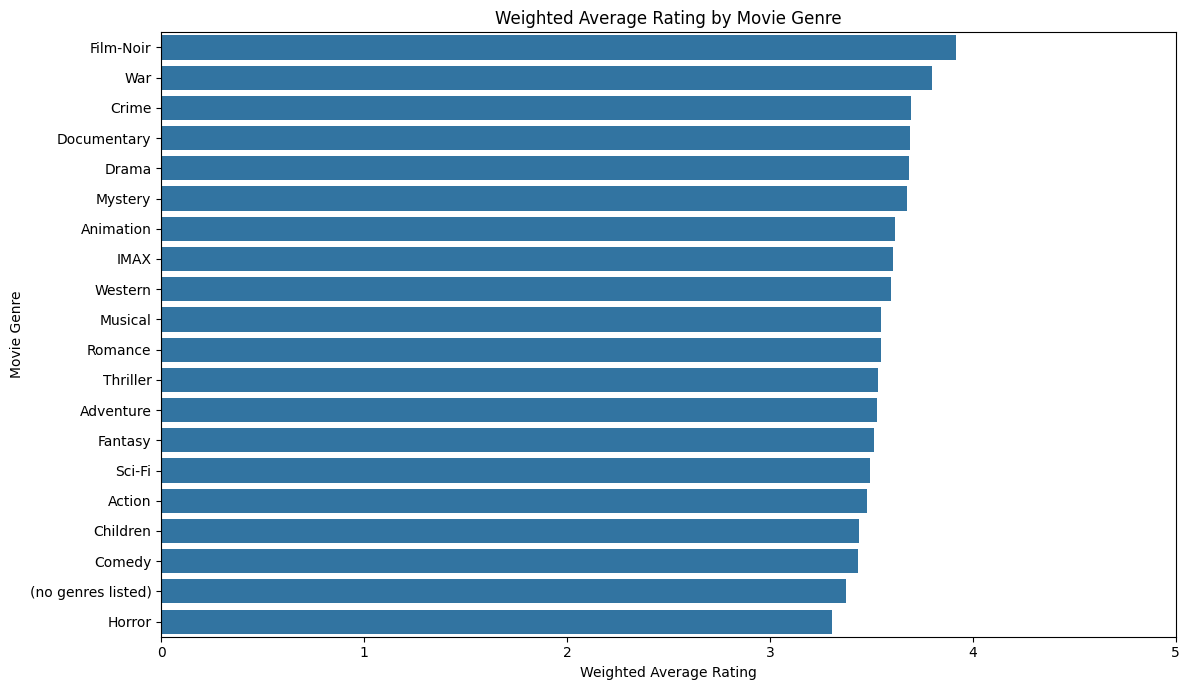

In [35]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=genre_weighted_ratings,
    x='weighted_average_rating',
    y='genres'
)

plt.title('Weighted Average Rating by Movie Genre')
plt.xlabel('Weighted Average Rating')
plt.ylabel('Movie Genre')
plt.xlim(0, 5)

plt.tight_layout()
plt.show()

In [36]:
# Load the first 10 rows of the tags dataset
tags_preview = pd.read_csv(
    "data/ml-latest/tags.csv",
    nrows=10
)

# Display the dataset
print("Dataset preview:")
display(tags_preview)

# Display column information
print("\nDataset information:")
tags_preview.info()

Dataset preview:


,userId,movieId,tag,timestamp
0,10,260,good vs evil,1430666558
1,10,260,Harrison Ford,1430666505
2,10,260,sci-fi,1430666538
3,14,1221,Al Pacino,1311600756
4,14,1221,mafia,1311600746
5,14,58559,Atmospheric,1311530439
6,14,58559,Batman,1311530391
7,14,58559,comic book,1311530398
8,14,58559,dark,1311530428
9,14,58559,Heath Ledger,1311530404



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   userId     10 non-null     int64 
 1   movieId    10 non-null     int64 
 2   tag        10 non-null     object
 3   timestamp  10 non-null     int64 
dtypes: int64(3), object(1)
memory usage: 448.0+ bytes


In [37]:
# Load the complete tags dataset
tags = pd.read_csv("data/ml-latest/tags.csv")

# Display basic dataset information
print("Dataset shape:", tags.shape)

print("\nDataset information:")
tags.info()

# Check missing values
print("\nMissing values:")
print(tags.isnull().sum())

# Count unique tags
print("\nUnique tags:", tags['tag'].nunique())

Dataset shape: (2328315, 4)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2328315 entries, 0 to 2328314
Data columns (total 4 columns):
 #   Column     Dtype 
---  ------     ----- 
 0   userId     int64 
 1   movieId    int64 
 2   tag        object
 3   timestamp  int64 
dtypes: int64(3), object(1)
memory usage: 71.1+ MB

Missing values:
userId        0
movieId       0
tag          17
timestamp     0
dtype: int64

Unique tags: 153949


In [38]:
# Create a copy of the tags dataset
tags_clean = tags.copy()

# Remove rows with missing tag values
tags_clean = tags_clean.dropna(subset=['tag'])

# Convert tags to lowercase and remove extra spaces
tags_clean['tag'] = (
    tags_clean['tag']
    .str.lower()
    .str.strip()
)

# Display cleaning results
print("Original records:", len(tags))
print("Cleaned records:", len(tags_clean))

print("Missing tags:", tags_clean['tag'].isnull().sum())
print("Unique tags after cleaning:", tags_clean['tag'].nunique())

# Display sample cleaned tags
tags_clean[['movieId', 'tag']].head(10)

Original records: 2328315
Cleaned records: 2328298
Missing tags: 0
Unique tags after cleaning: 143263


,movieId,tag
0,260,good vs evil
1,260,harrison ford
2,260,sci-fi
3,1221,al pacino
4,1221,mafia
5,58559,atmospheric
6,58559,batman
7,58559,comic book
8,58559,dark
9,58559,heath ledger


In [39]:
# Count how frequently each tag appears
tag_counts = tags_clean['tag'].value_counts()

# Select the 20 most frequently used tags
top_20_tags = tag_counts.head(20)

# Display the results
print("Top 20 most frequently used tags:")
print(top_20_tags)

Top 20 most frequently used tags:
tag
sci-fi                14917
atmospheric           12776
action                11754
comedy                11606
funny                  9851
surreal                9443
visually appealing     9086
twist ending           8428
dark comedy            7777
thought-provoking      7731
based on a book        7725
romance                7435
dystopia               7056
cinematography         6645
fantasy                6476
social commentary      6426
violence               6414
thriller               6384
stylized               6201
classic                6183
Name: count, dtype: int64


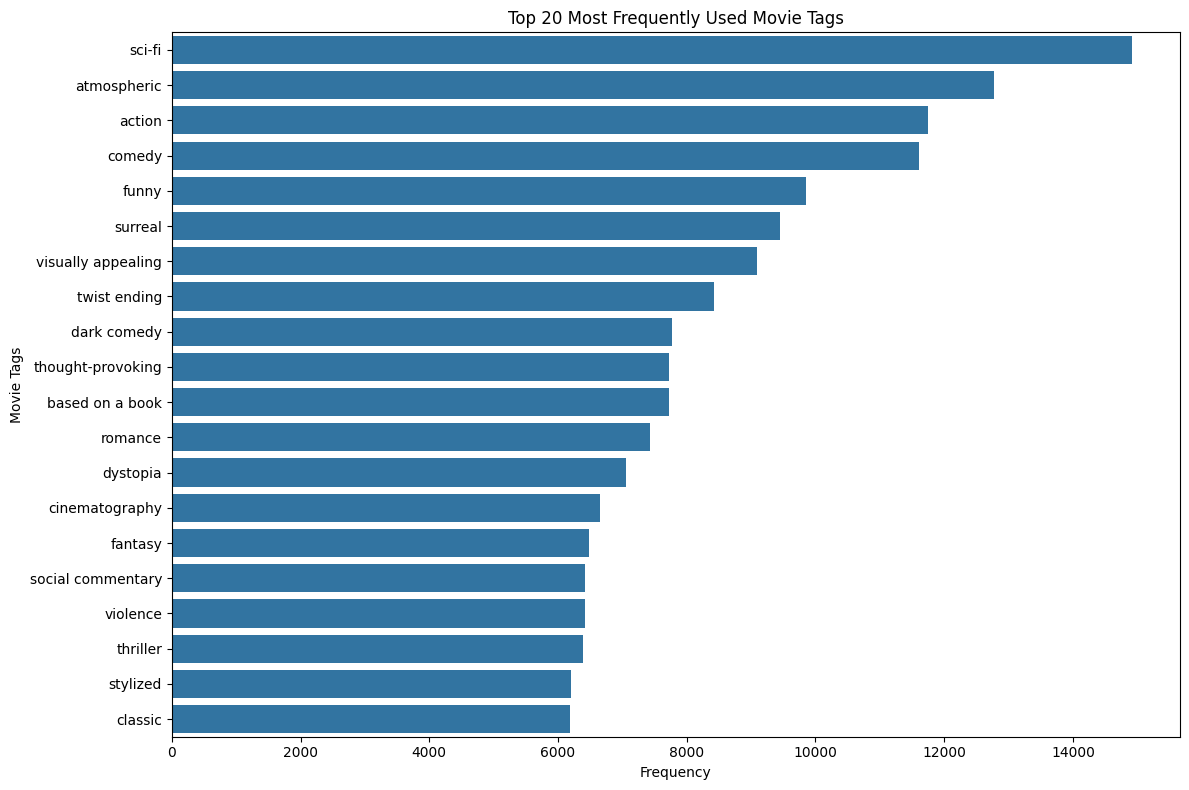

In [40]:
plt.figure(figsize=(12, 8))

sns.barplot(
    x=top_20_tags.values,
    y=top_20_tags.index
)

plt.title('Top 20 Most Frequently Used Movie Tags')
plt.xlabel('Frequency')
plt.ylabel('Movie Tags')

plt.tight_layout()
plt.show()

Analyse how many tags each movie receives

In [41]:
# Count the number of tags assigned to each movie
movie_tag_counts = tags_clean.groupby('movieId')['tag'].count()

# Display basic statistics
print("Tag distribution across movies:")
print(movie_tag_counts.describe())

# Display the 10 movies with the most tags
print("\nTop 10 movies by number of tags:")
print(movie_tag_counts.sort_values(ascending=False).head(10))

Tag distribution across movies:
count    53452.000000
mean        43.558669
std        197.466091
min          1.000000
25%          2.000000
50%          6.000000
75%         18.000000
max      11152.000000
Name: tag, dtype: float64

Top 10 movies by number of tags:
movieId
260       11152
79132      8978
296        8753
2571       7593
2959       7459
109487     7331
318        6839
356        4880
7361       4680
4226       4675
Name: tag, dtype: int64


Visualize tag distribution across movies

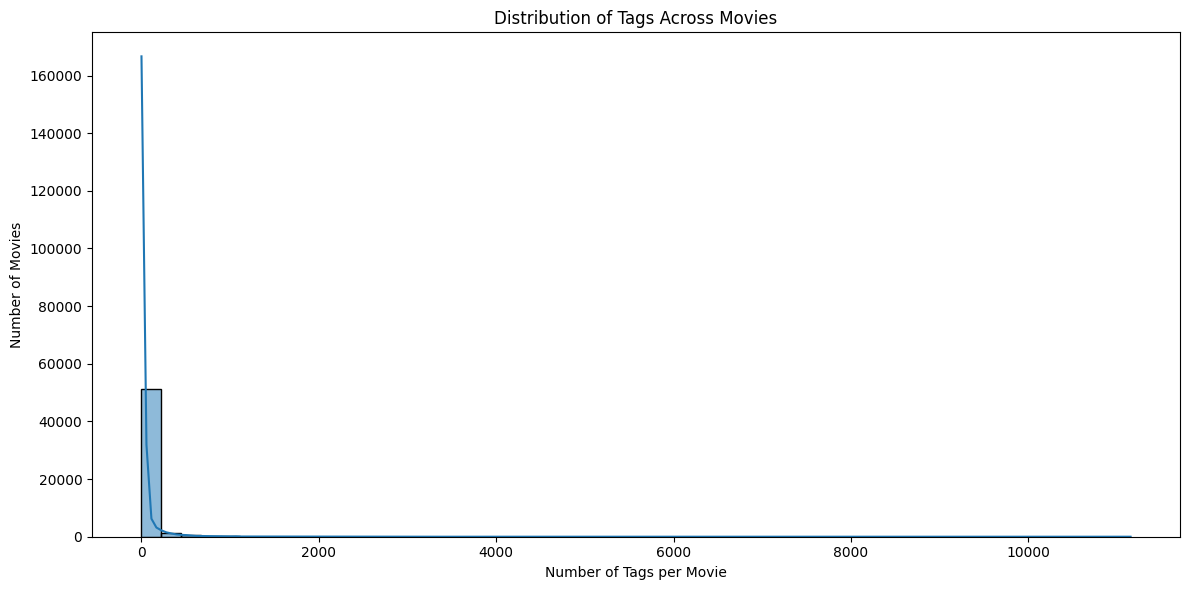

In [42]:
plt.figure(figsize=(12, 6))

sns.histplot(
    movie_tag_counts,
    bins=50,
    kde=True
)

plt.title('Distribution of Tags Across Movies')
plt.xlabel('Number of Tags per Movie')
plt.ylabel('Number of Movies')

plt.tight_layout()
plt.show()

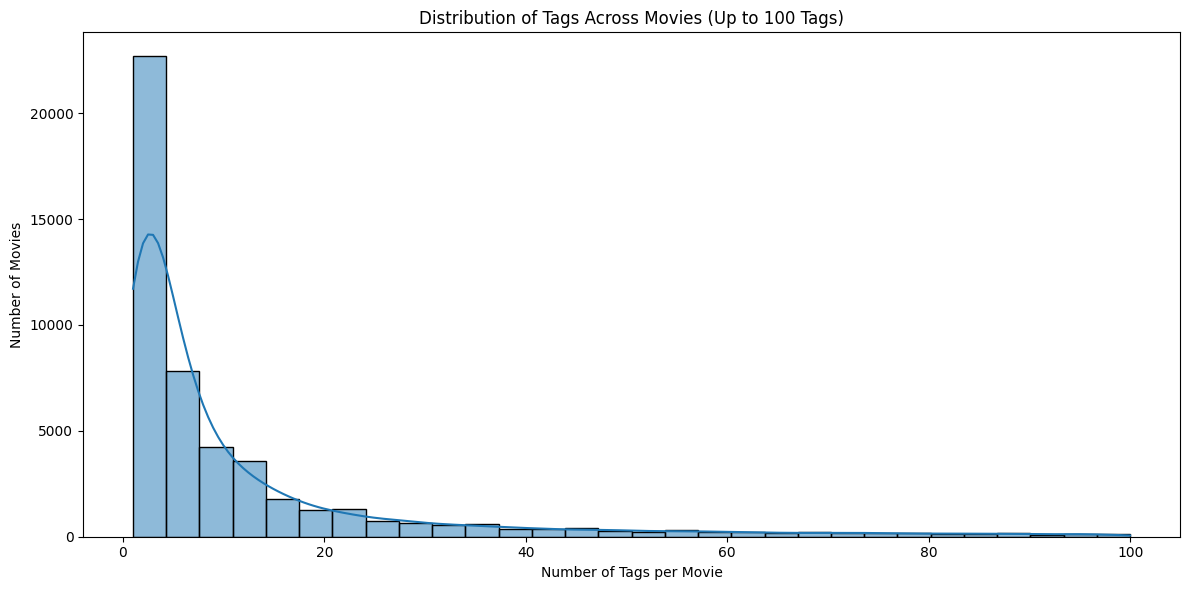

In [43]:
# alternative visualization
# Keep movies with 100 or fewer tags;just  for visualization
movie_tag_counts_filtered = movie_tag_counts[
    movie_tag_counts <= 100
]

plt.figure(figsize=(12, 6))

sns.histplot(
    movie_tag_counts_filtered,
    bins=30,
    kde=True
)

plt.title('Distribution of Tags Across Movies (Up to 100 Tags)')
plt.xlabel('Number of Tags per Movie')
plt.ylabel('Number of Movies')

plt.tight_layout()
plt.show()

Identify movies with insufficient tag information

In [44]:
# Categorize movies based on their number of tags
tag_categories = pd.cut(
    movie_tag_counts,
    bins=[0, 5, 10, 20, float('inf')],
    labels=['1-5 tags', '6-10 tags', '11-20 tags', 'Above 20 tags']
)

# Count movies in each category
tag_distribution = tag_categories.value_counts().sort_index()

# Display the results
print("Movie distribution by tag count:")
print(tag_distribution)

Movie distribution by tag count:
tag
1-5 tags         25933
6-10 tags         8824
11-20 tags        6594
Above 20 tags    12101
Name: count, dtype: int64


Investigate movies without tags

In [45]:
# Total number of unique movies
total_movies = movies['movieId'].nunique()

# Number of movies that have at least one tag
movies_with_tags = movie_tag_counts.index.nunique()

# Calculate movies without tags
movies_without_tags = total_movies - movies_with_tags

# Calculate tag coverage percentage
tag_coverage = (movies_with_tags / total_movies) * 100

# Display results
print("Total movies:", total_movies)
print("Movies with tags:", movies_with_tags)
print("Movies without tags:", movies_without_tags)
print("Tag coverage:", round(tag_coverage, 2), "%")

Total movies: 86537
Movies with tags: 53452
Movies without tags: 33085
Tag coverage: 61.77 %


Prepare movie genres and tags for NLP

In [47]:
# Group all tags belonging to each movie
movie_tags = tags_clean.groupby('movieId')['tag'].apply(
    lambda x: ' '.join(x)
).reset_index()

# Merge tags with movie information
movie_features = movies.merge(
    movie_tags,
    on='movieId',
    how='left'
)

# Replace missing tags with empty strings
movie_features['tag'] = movie_features['tag'].fillna('')

# Clean genre text
movie_features['genres'] = (
    movie_features['genres']
    .str.replace('|', ' ', regex=False)
)

# Combine genres and tags
movie_features['combined_features'] = (
    movie_features['genres'] + ' ' +
    movie_features['tag']
)

# Display sample movie features
movie_features[['title', 'genres', 'tag', 'combined_features']].head(10)

,title,genres,tag,combined_features
0,Toy Story (1995),Adventure Animation Children Comedy Fantasy,animation friendship toys animation disney pix...,Adventure Animation Children Comedy Fantasy an...
1,Jumanji (1995),Adventure Children Fantasy,animals based on a book fantasy magic board ga...,Adventure Children Fantasy animals based on a ...
2,Grumpier Old Men (1995),Comedy Romance,sequel moldy old old age old men wedding old p...,Comedy Romance sequel moldy old old age old me...
3,Waiting to Exhale (1995),Comedy Drama Romance,characters chick flick girl movie characters c...,Comedy Drama Romance characters chick flick gi...
4,Father of the Bride Part II (1995),Comedy,family pregnancy wedding 4th wall aging baby d...,Comedy family pregnancy wedding 4th wall aging...
5,Heat (1995),Action Crime Thriller,al pacino complex characters crime philosophy ...,Action Crime Thriller al pacino complex charac...
6,Sabrina (1995),Comedy Romance,based on a play harrison ford paris romance si...,Comedy Romance based on a play harrison ford p...
7,Tom and Huck (1995),Adventure Children,adapted from:book author:mark twain prospect p...,Adventure Children adapted from:book author:ma...
8,Sudden Death (1995),Action,jean-claude van damme can't remember clv 1990s...,Action jean-claude van damme can't remember cl...
9,GoldenEye (1995),Action Adventure Thriller,its an ok movie if you like james bound. 007 ...,Action Adventure Thriller its an ok movie if y...


Verify our combined dataset

In [48]:
# Check the shape of the combined dataset
print("Combined dataset shape:", movie_features.shape)

# Check missing values
print("\nMissing values:")
print(movie_features[
    ['genres', 'tag', 'combined_features']
].isnull().sum())

# Count movies with empty tags
empty_tag_count = (movie_features['tag'] == '').sum()

print("\nMovies with empty tags:", empty_tag_count)

# Display a few records
movie_features[
    ['title', 'combined_features']
].head(5)

Combined dataset shape: (86537, 7)

Missing values:
genres               0
tag                  0
combined_features    0
dtype: int64

Movies with empty tags: 33085


,title,combined_features
0,Toy Story (1995),Adventure Animation Children Comedy Fantasy an...
1,Jumanji (1995),Adventure Children Fantasy animals based on a ...
2,Grumpier Old Men (1995),Comedy Romance sequel moldy old old age old me...
3,Waiting to Exhale (1995),Comedy Drama Romance characters chick flick gi...
4,Father of the Bride Part II (1995),Comedy family pregnancy wedding 4th wall aging...


NLP preprocessing: Tokenization

In [49]:
# Select the combined text of the first movie
sample_text = movie_features.loc[0, 'combined_features']

# Display original text
print("Original text:")
print(sample_text)

# Tokenize the text
tokens = sample_text.split()

# Display tokens
print("\nTokens:")
print(tokens)

# Count tokens
print("\nNumber of tokens:", len(tokens))

Original text:
Adventure Animation Children Comedy Fantasy animation friendship toys animation disney pixar toys cgi classic disney pixar lots of heart tom hanks clever funny pixar witty animation comedy kids pixar tom hanks toy story toys animated fun jealousy funny witty adventure animation comedy family fantasy john lasseter usa family film friendship toys disney dolls national film registry buddy movie tom hanks witty pixar adventure clever enemies become friends family family cartoon family relationships feel-good first of series friends friendship fun fun family movie heroic mission humorous jealousy kids kids movie loyal friend loyalty redemption reflection rescue mission rivalry selflessness teamwork unlikely friendships unusual friendship witty os dois viram adventure animated animation cgi comedy disney family fantasy friendship imdb top 250 pixar tom hanks witty classic disney friendship pixar accepting reality emotional friendship funny soundtrack humorous pixar tumey's to 

Stop word removal

In [50]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# Convert text to lowercase
lowercase_text = sample_text.lower()

# Split text into tokens
tokens = lowercase_text.split()

# Remove stop words
filtered_tokens = [
    word for word in tokens
    if word not in ENGLISH_STOP_WORDS
]

# Display results
print("Original token count:", len(tokens))
print("Tokens after stop word removal:", len(filtered_tokens))

print("\nOriginal tokens (first 30):")
print(tokens[:30])

print("\nFiltered tokens (first 30):")
print(filtered_tokens[:30])

Original token count: 2010
Tokens after stop word removal: 1900

Original tokens (first 30):
['adventure', 'animation', 'children', 'comedy', 'fantasy', 'animation', 'friendship', 'toys', 'animation', 'disney', 'pixar', 'toys', 'cgi', 'classic', 'disney', 'pixar', 'lots', 'of', 'heart', 'tom', 'hanks', 'clever', 'funny', 'pixar', 'witty', 'animation', 'comedy', 'kids', 'pixar', 'tom']

Filtered tokens (first 30):
['adventure', 'animation', 'children', 'comedy', 'fantasy', 'animation', 'friendship', 'toys', 'animation', 'disney', 'pixar', 'toys', 'cgi', 'classic', 'disney', 'pixar', 'lots', 'heart', 'tom', 'hanks', 'clever', 'funny', 'pixar', 'witty', 'animation', 'comedy', 'kids', 'pixar', 'tom', 'hanks']


Stemming

In [51]:
# Import Porter Stemmer
from nltk.stem import PorterStemmer

# Create a stemmer object
stemmer = PorterStemmer()

# Example words
words = ['playing', 'played', 'player', 'movies', 'connected', 'friendship']

# Apply stemming
stemmed_words = [stemmer.stem(word) for word in words]

# Display results
for original, stemmed in zip(words, stemmed_words):
    print(f"{original} -> {stemmed}")

playing -> play
played -> play
player -> player
movies -> movi
connected -> connect
friendship -> friendship


Lemmatization

In [52]:
# Import WordNetLemmatizer
from nltk.stem import WordNetLemmatizer

# Create a lemmatizer object
lemmatizer = WordNetLemmatizer()

# Example words
words = ['playing', 'played', 'movies', 'better', 'studies', 'cars']

# Apply lemmatization
lemmatized_words = [
    lemmatizer.lemmatize(word)
    for word in words
]

# Display results
for original, lemma in zip(words, lemmatized_words):
    print(f"{original} -> {lemma}")

playing -> playing
played -> played
movies -> movie
better -> better
studies -> study
cars -> car


TF-IDF Vectorization

TF-IDF stands for:

Term Frequency – Inverse Document Frequency

In [53]:
# Import TF-IDF Vectorizer
from sklearn.feature_extraction.text import TfidfVectorizer

# Create three sample movie descriptions
sample_movies = [
    "space science fiction adventure",
    "space aliens science fiction",
    "romance love relationship"
]

# Create TF-IDF vectorizer
tfidf = TfidfVectorizer()

# Convert text into numerical features
tfidf_matrix = tfidf.fit_transform(sample_movies)

# Display vocabulary
print("Vocabulary:")
print(tfidf.get_feature_names_out())

# Display TF-IDF matrix
print("\nTF-IDF Matrix:")
print(tfidf_matrix.toarray())

Vocabulary:
['adventure' 'aliens' 'fiction' 'love' 'relationship' 'romance' 'science'
 'space']

TF-IDF Matrix:
[[0.60465213 0.         0.45985353 0.         0.         0.
  0.45985353 0.45985353]
 [0.         0.60465213 0.45985353 0.         0.         0.
  0.45985353 0.45985353]
 [0.         0.         0.         0.57735027 0.57735027 0.57735027
  0.         0.        ]]


Understand the similarity between movies

In [54]:
# Import cosine similarity
from sklearn.metrics.pairwise import cosine_similarity

# Calculate similarity between all three movies
similarity_matrix = cosine_similarity(tfidf_matrix)

# Display similarity matrix
print("Cosine Similarity Matrix:")
print(similarity_matrix)

# Compare Movie A and Movie B
print("\nSimilarity between Movie A and Movie B:")
print(round(similarity_matrix[0, 1], 3))

# Compare Movie A and Movie C
print("\nSimilarity between Movie A and Movie C:")
print(round(similarity_matrix[0, 2], 3))

Cosine Similarity Matrix:
[[1.        0.6343958 0.       ]
 [0.6343958 1.        0.       ]
 [0.        0.        1.       ]]

Similarity between Movie A and Movie B:
0.634

Similarity between Movie A and Movie C:
0.0


Concept	What it does:

TF-IDF	-  Converts text into weighted numerical features

Vector	-  Numerical representation of a movie

Cosine similarity	-  Measures similarity between two vectors

Similarity matrix	-  Stores pairwise similarity scores

Apply TF-IDF to our actual movie dataset